# Plot real-data analysis results

Given an analysis directory written by `run_real_data_analysis.py`, produces:

1. Per-condition consistency across K resampling rounds — D marginal, R0 marginal, free-energy landscape.
2. Free-energy landscape overlay across glycerol conditions.
3. D as a function of glycerol %.
4. Free-energy landscape overlay across ionic strength.
5. R0 posterior marginals for all conditions.

Edit `ANALYSIS_DIR` below — nothing else is condition-specific.

In [6]:
ANALYSIS_DIR = "/home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/analysis/exp_8/2026-05-06/13-36-28/"

import json, re, sys
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.stats import gaussian_kde
from omegaconf import OmegaConf

ROOT = Path("/home/dingeldein/Desktop/fret_sbi")
SRC = ROOT / "smFRET_sbi" / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from utils import eval_free_energy_from_config  # noqa: E402

ANALYSIS_DIR = Path(ANALYSIS_DIR)
run_meta = json.loads((ANALYSIS_DIR / "run_meta.json").read_text())
data_cfg = OmegaConf.load(run_meta["data_config_path"])
eval_F = eval_free_energy_from_config(data_cfg)

NUM_KNOTS = int(data_cfg.prior.num_knots)
R0_IDX = NUM_KNOTS + 1
LOGD_IDX = 0

knot_spacing = (data_cfg.simulator.x_max - data_cfg.simulator.x_min) / (NUM_KNOTS - 1)
x_plot_margin = 0.6 * data_cfg.simulator.num_boundary_knots * knot_spacing
x_eval = np.linspace(
    data_cfg.simulator.x_min - x_plot_margin,
    data_cfg.simulator.x_max + x_plot_margin,
    500,
)

PLOTS_DIR = ANALYSIS_DIR / "plots"
PLOTS_DIR.mkdir(exist_ok=True)

print(f"analysis dir : {ANALYSIS_DIR}")
print(f"conditions   : {len(run_meta['conditions'])}")
print(f"num rounds   : {run_meta['num_rounds']}")
print(f"theta dim    : {run_meta['theta_dim']}  (num_knots={NUM_KNOTS})")
print(f"x_eval range : [{x_eval[0]:.2f}, {x_eval[-1]:.2f}] nm, {len(x_eval)} pts")

analysis dir : /home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/analysis/exp_8/2026-05-06/13-36-28
conditions   : 1
num rounds   : 3
theta dim    : 9  (num_knots=7)
x_eval range : [2.50, 10.50] nm, 500 pts


In [7]:
def load_condition(cond):
    """Load all `round_*` results for a single condition. Returns None if missing."""
    cond_dir = ANALYSIS_DIR / cond
    if not cond_dir.exists():
        return None
    round_dirs = sorted([d for d in cond_dir.iterdir() if d.is_dir() and d.name.startswith("round_")])
    if not round_dirs:
        return None
    samples_list = []
    maps_list = []
    for rd in round_dirs:
        s_path = rd / "posterior_samples.pt"
        m_path = rd / "map_estimate.pt"
        if not (s_path.exists() and m_path.exists()):
            continue
        samples_list.append(torch.load(s_path, map_location="cpu").float())
        maps_list.append(torch.load(m_path, map_location="cpu").float())
    if not maps_list:
        return None
    return {
        "samples": samples_list,               # list of (N, 9) tensors
        "maps": torch.stack(maps_list),         # (K, 9)
        "rounds": [rd.name for rd in round_dirs[: len(maps_list)]],
    }


_GLYC_RE = re.compile(r"_(\d+)%glycerol")
_NACL_RE = re.compile(r"_(\d+)mMNaCl")
_NAPI_RE = re.compile(r"_(\d+)mMNaPi")


def parse_condition(name):
    g = _GLYC_RE.search(name)
    c = _NACL_RE.search(name)
    p = _NAPI_RE.search(name)
    glyc = int(g.group(1)) if g else 0
    nacl = int(c.group(1)) if c else 0
    napi = int(p.group(1)) if p else 0
    return {
        "glycerol_pct": glyc,
        "nacl_mM": nacl,
        "napi_mM": napi,
        "ionic_mM": napi + nacl,
        "cy3b": "Cy3B" in name,
        "reverse": name.startswith("NCBD-avi"),
    }


def F_from_theta(theta_1d):
    _, y = eval_F(params=theta_1d, x_eval=x_eval)
    return y


def align_to(y, y_ref):
    return y + float(np.mean(y_ref - y))


def kde_line(values, x_lo, x_hi, n=200, bw=None):
    values = np.asarray(values).ravel()
    if values.std() < 1e-10:
        xs = np.linspace(x_lo, x_hi, n)
        ys = np.zeros_like(xs)
        ys[np.argmin(np.abs(xs - values.mean()))] = 1.0
        return xs, ys
    kde = gaussian_kde(values, bw_method=bw)
    xs = np.linspace(x_lo, x_hi, n)
    return xs, kde(xs)


# Cache — load every condition once.
results = {}
for cond in run_meta["conditions"]:
    r = load_condition(cond)
    if r is not None:
        results[cond] = r
print(f"loaded {len(results)}/{len(run_meta['conditions'])} conditions")
for cond, r in results.items():
    print(f"  {cond:60s} K={r['maps'].shape[0]}")

loaded 1/1 conditions
  ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_50mMNaCl                  K=3


/tmp/ipykernel_776076/181466284.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  samples_list.append(torch.load(s_path, map_location="cpu").float())
/tmp/ipykernel_77607

## Figure 1 — per-condition consistency across K rounds

For each condition: three panels side-by-side.
- D marginal from round 0 + K vertical lines for MAP D values.
- R0 marginal from round 0 + K vertical lines for MAP R0 values.
- F(x): posterior band (1000 grey samples) + K MAP curves, all aligned to round-0 MAP. Secondary FRET-efficiency axis.

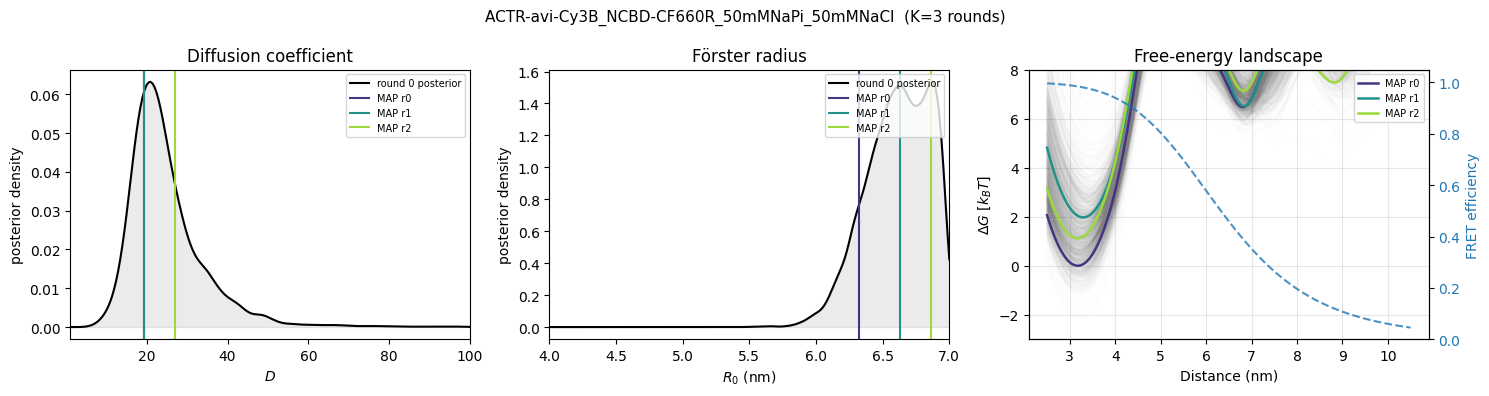

In [8]:
N_BAND_SAMPLES = 1000
logD_lims = tuple(data_cfg.prior.logD_lims)
R0_lims = tuple(data_cfg.prior.R0_lims)

for cond, r in results.items():
    samples0 = r["samples"][0].numpy()
    maps = r["maps"].numpy()
    K = maps.shape[0]
    round_colors = cm.viridis(np.linspace(0.15, 0.85, K))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # --- D panel
    ax = axes[0]
    D_post = 10.0 ** samples0[:, LOGD_IDX]
    D_lo, D_hi = 10.0 ** logD_lims[0], 10.0 ** logD_lims[1]
    xs, ys = kde_line(D_post, D_lo, D_hi)
    ax.plot(xs, ys, color="black", lw=1.5, label="round 0 posterior")
    ax.fill_between(xs, 0, ys, color="black", alpha=0.08)
    for k in range(K):
        ax.axvline(10.0 ** maps[k, LOGD_IDX], color=round_colors[k], lw=1.5, label=f"MAP r{k}")
    ax.set_xlim(D_lo, D_hi)
    ax.set_xlabel(r"$D$")
    ax.set_ylabel("posterior density")
    ax.set_title("Diffusion coefficient")
    ax.legend(fontsize=7, loc="upper right")

    # --- R0 panel
    ax = axes[1]
    R0_post = samples0[:, R0_IDX]
    xs, ys = kde_line(R0_post, R0_lims[0], R0_lims[1])
    ax.plot(xs, ys, color="black", lw=1.5, label="round 0 posterior")
    ax.fill_between(xs, 0, ys, color="black", alpha=0.08)
    for k in range(K):
        ax.axvline(maps[k, R0_IDX], color=round_colors[k], lw=1.5, label=f"MAP r{k}")
    ax.set_xlim(R0_lims)
    ax.set_xlabel(r"$R_0$ (nm)")
    ax.set_ylabel("posterior density")
    ax.set_title("Förster radius")
    ax.legend(fontsize=7, loc="upper right")

    # --- F(x) panel
    ax = axes[2]
    F_map0 = F_from_theta(maps[0])
    F_ref = F_map0 - F_map0.min()

    n_band = min(N_BAND_SAMPLES, samples0.shape[0])
    band_idx = np.random.default_rng(0).choice(samples0.shape[0], size=n_band, replace=False)
    for i in band_idx:
        y_s = F_from_theta(samples0[i])
        ax.plot(x_eval, align_to(y_s, F_ref), color="gray", alpha=0.01)

    for k in range(K):
        y_k = F_from_theta(maps[k])
        ax.plot(x_eval, align_to(y_k, F_ref), color=round_colors[k], lw=1.8, label=f"MAP r{k}")

    ax.set_xlabel("Distance (nm)")
    ax.set_ylabel(r"$\Delta G\ [k_{B}T]$")
    ax.set_ylim(-3, 8)
    ax.set_title("Free-energy landscape")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper right")

    # FRET efficiency on twin axis
    R0_ref = float(maps[0, R0_IDX])
    r_arr = np.clip(x_eval, 1e-9, None)
    E = 1.0 / (1.0 + (r_arr / R0_ref) ** 6)
    ax_e = ax.twinx()
    ax_e.plot(x_eval, E, color="tab:blue", ls="--", lw=1.5, alpha=0.8)
    ax_e.set_ylabel("FRET efficiency", color="tab:blue")
    ax_e.tick_params(axis="y", labelcolor="tab:blue")
    ax_e.set_ylim(0, 1.05)

    fig.suptitle(f"{cond}  (K={K} rounds)", fontsize=11)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"fig1_consistency__{cond}.png", dpi=150)
    plt.show()

## Figure 2 — free-energy overlay across glycerol

Mean-of-MAP F(x) across rounds, ±1σ band, aligned to the 0%-glycerol reference.

In [5]:
# Conditions that belong to the glycerol series (same base label).
def is_glycerol_series(cond):
    meta = parse_condition(cond)
    return (
        cond.startswith("ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi")
        and meta["nacl_mM"] == 0
        and not meta["reverse"]
    )

glyc_conds = [c for c in results if is_glycerol_series(c)]
glyc_conds = sorted(glyc_conds, key=lambda c: parse_condition(c)["glycerol_pct"])
print("glycerol conditions used:")
for c in glyc_conds:
    print(f"  {parse_condition(c)['glycerol_pct']:>3d} %   {c}")

if glyc_conds:
    # Reference = 0% glycerol if present, else first condition.
    ref_cond = next((c for c in glyc_conds if parse_condition(c)["glycerol_pct"] == 0), glyc_conds[0])
    F_ref = F_from_theta(results[ref_cond]["maps"][0].numpy())
    F_ref = F_ref - F_ref.min()

    fig, ax = plt.subplots(figsize=(7, 4.5))
    cmap = cm.viridis
    glyc_vals = [parse_condition(c)["glycerol_pct"] for c in glyc_conds]
    vmin, vmax = min(glyc_vals), max(max(glyc_vals), 1)

    for cond in glyc_conds:
        maps = results[cond]["maps"].numpy()
        Fs = np.stack([F_from_theta(m) for m in maps], axis=0)  # (K, len(x_eval))
        Fs_aligned = np.stack([align_to(f, F_ref) for f in Fs], axis=0)
        mu = Fs_aligned.mean(axis=0)
        sd = Fs_aligned.std(axis=0)
        pct = parse_condition(cond)["glycerol_pct"]
        col = cmap((pct - vmin) / max(vmax - vmin, 1))
        ax.plot(x_eval, mu, color=col, lw=2.0, label=f"{pct}% glycerol")
        ax.fill_between(x_eval, mu - sd, mu + sd, color=col, alpha=0.2)

    ax.set_xlabel("Distance (nm)")
    ax.set_ylabel(r"$\Delta G\ [k_{B}T]$")
    ax.set_ylim(-3, 8)
    ax.set_title("Free-energy landscape vs glycerol")
    ax.grid(alpha=0.3)
    ax.legend(loc="best")
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "fig2_F_vs_glycerol.png", dpi=150)
    plt.show()
else:
    print("No glycerol conditions available in this analysis dir.")

glycerol conditions used:
No glycerol conditions available in this analysis dir.


## Figure 3 — D vs glycerol %

Median MAP-D across rounds with MAD errorbars; posterior-median D from round 0 plotted faintly for comparison.

In [6]:
if glyc_conds:
    fig, ax = plt.subplots(figsize=(6, 4))
    xs, D_meds, D_mads, D_postmeds = [], [], [], []
    for cond in glyc_conds:
        pct = parse_condition(cond)["glycerol_pct"]
        maps = results[cond]["maps"].numpy()
        D_ks = 10.0 ** maps[:, LOGD_IDX]
        med = float(np.median(D_ks))
        mad = float(np.median(np.abs(D_ks - med)))
        xs.append(pct)
        D_meds.append(med)
        D_mads.append(mad)
        D_postmeds.append(float(np.median(10.0 ** results[cond]["samples"][0].numpy()[:, LOGD_IDX])))

    ax.errorbar(xs, D_meds, yerr=D_mads, fmt="o", color="black", lw=1.5, capsize=3,
                label="median MAP ± MAD (across rounds)")
    ax.scatter(xs, D_postmeds, marker="x", color="tab:red", alpha=0.6,
               label="round-0 posterior median")
    ax.set_xlabel("Glycerol (%)")
    ax.set_ylabel(r"$D$")
    ax.set_title("Diffusion coefficient vs glycerol")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "fig3_D_vs_glycerol.png", dpi=150)
    plt.show()
else:
    print("No glycerol conditions available in this analysis dir.")

No glycerol conditions available in this analysis dir.


## Figure 4 — free-energy overlay across ionic strength

Same recipe as Figure 2 but over the NaCl series (plus the 20 mM NaPi / 10 mM NaCl condition). Colour = total ionic strength (NaPi + NaCl).

ionic-strength conditions used:
  I= 100 mM  (NaPi=50, NaCl=50)   ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_50mMNaCl


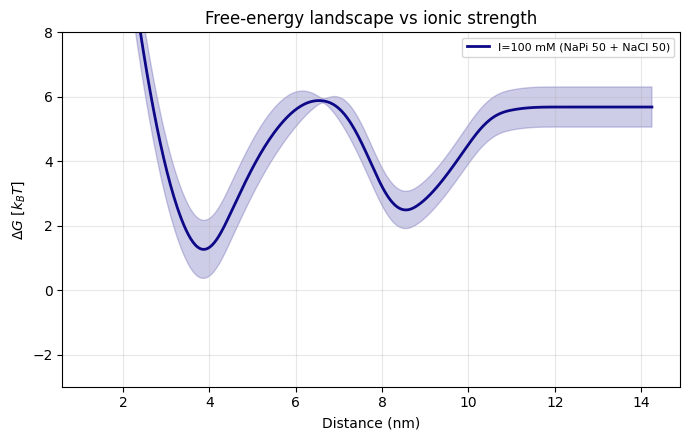

In [7]:
def is_ionic_series(cond):
    meta = parse_condition(cond)
    return (
        meta["glycerol_pct"] == 0
        and meta["cy3b"]
        and not meta["reverse"]
    )

ionic_conds = [c for c in results if is_ionic_series(c)]
ionic_conds = sorted(ionic_conds, key=lambda c: parse_condition(c)["ionic_mM"])
print("ionic-strength conditions used:")
for c in ionic_conds:
    m = parse_condition(c)
    print(f"  I={m['ionic_mM']:>4d} mM  (NaPi={m['napi_mM']}, NaCl={m['nacl_mM']})   {c}")

if ionic_conds:
    # Reference = lowest ionic strength that is Cy3B & 50 mM NaPi & 0 NaCl, else smallest I.
    ref_cond = next(
        (c for c in ionic_conds if parse_condition(c)["napi_mM"] == 50 and parse_condition(c)["nacl_mM"] == 0),
        ionic_conds[0],
    )
    F_ref = F_from_theta(results[ref_cond]["maps"][0].numpy())
    F_ref = F_ref - F_ref.min()

    fig, ax = plt.subplots(figsize=(7, 4.5))
    cmap = cm.plasma
    ivals = [parse_condition(c)["ionic_mM"] for c in ionic_conds]
    vmin, vmax = min(ivals), max(ivals)

    for cond in ionic_conds:
        maps = results[cond]["maps"].numpy()
        Fs = np.stack([F_from_theta(m) for m in maps], axis=0)
        Fs_aligned = np.stack([align_to(f, F_ref) for f in Fs], axis=0)
        mu = Fs_aligned.mean(axis=0)
        sd = Fs_aligned.std(axis=0)
        meta = parse_condition(cond)
        I = meta["ionic_mM"]
        col = cmap((I - vmin) / max(vmax - vmin, 1))
        label = f"I={I} mM (NaPi {meta['napi_mM']} + NaCl {meta['nacl_mM']})"
        ax.plot(x_eval, mu, color=col, lw=2.0, label=label)
        ax.fill_between(x_eval, mu - sd, mu + sd, color=col, alpha=0.2)

    ax.set_xlabel("Distance (nm)")
    ax.set_ylabel(r"$\Delta G\ [k_{B}T]$")
    ax.set_ylim(-3, 8)
    ax.set_title("Free-energy landscape vs ionic strength")
    ax.grid(alpha=0.3)
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "fig4_F_vs_ionic.png", dpi=150)
    plt.show()
else:
    print("No ionic-strength conditions available in this analysis dir.")

## Figure 5 — R0 posterior marginals, all conditions

Round-0 KDE of R0 per condition, on a shared x-axis.

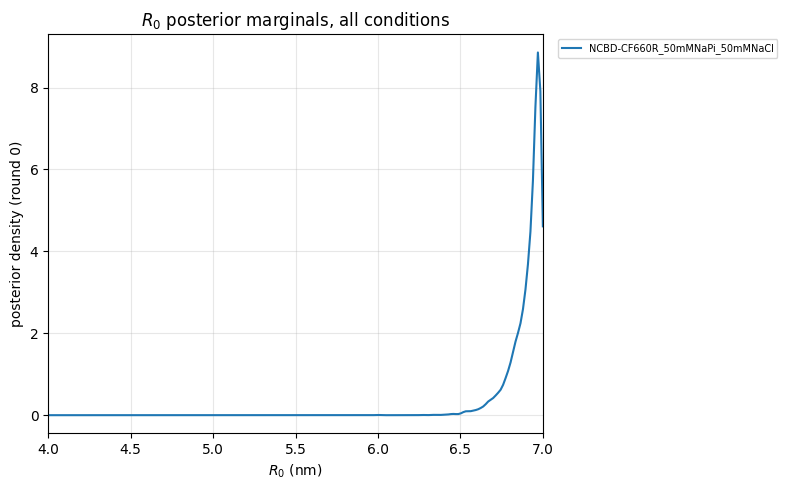

In [8]:
if results:
    fig, ax = plt.subplots(figsize=(8, 5))
    conds_sorted = sorted(
        results.keys(),
        key=lambda c: (parse_condition(c)["glycerol_pct"], parse_condition(c)["ionic_mM"], c),
    )
    colors = cm.tab20(np.linspace(0, 1, len(conds_sorted)))
    for col, cond in zip(colors, conds_sorted):
        R0_post = results[cond]["samples"][0].numpy()[:, R0_IDX]
        xs, ys = kde_line(R0_post, R0_lims[0], R0_lims[1])
        meta = parse_condition(cond)
        short = cond.split("_", 1)[-1] if "_" in cond else cond
        ax.plot(xs, ys, color=col, lw=1.5, label=short)
    ax.set_xlim(R0_lims)
    ax.set_xlabel(r"$R_0$ (nm)")
    ax.set_ylabel("posterior density (round 0)")
    ax.set_title(r"$R_0$ posterior marginals, all conditions")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper left", ncol=1, bbox_to_anchor=(1.02, 1.0))
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "fig5_R0_marginals.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No conditions loaded.")

## Figure 6 — D vs ionic strength

Median MAP-D across rounds with MAD errorbars; posterior-median D from round 0 plotted faintly for comparison. Uses the same ionic-strength series as Figure 4.

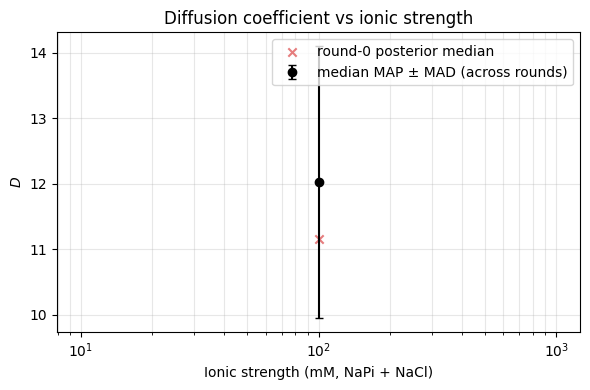

In [9]:
if ionic_conds:
    fig, ax = plt.subplots(figsize=(6, 4))
    xs, D_meds, D_mads, D_postmeds = [], [], [], []
    for cond in ionic_conds:
        I = parse_condition(cond)["ionic_mM"]
        maps = results[cond]["maps"].numpy()
        D_ks = 10.0 ** maps[:, LOGD_IDX]
        med = float(np.median(D_ks))
        mad = float(np.median(np.abs(D_ks - med)))
        xs.append(I)
        D_meds.append(med)
        D_mads.append(mad)
        D_postmeds.append(float(np.median(10.0 ** results[cond]["samples"][0].numpy()[:, LOGD_IDX])))

    ax.errorbar(xs, D_meds, yerr=D_mads, fmt="o", color="black", lw=1.5, capsize=3,
                label="median MAP ± MAD (across rounds)")
    ax.scatter(xs, D_postmeds, marker="x", color="tab:red", alpha=0.6,
               label="round-0 posterior median")
    ax.set_xlabel("Ionic strength (mM, NaPi + NaCl)")
    ax.set_ylabel(r"$D$")
    ax.set_title("Diffusion coefficient vs ionic strength")
    ax.set_xscale("log")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / "fig6_D_vs_ionic.png", dpi=150)
    plt.show()
else:
    print("No ionic-strength conditions available in this analysis dir.")

In [10]:
print(f"plots written to: {PLOTS_DIR}")
for p in sorted(PLOTS_DIR.glob("*.png")):
    print(f"  {p.name}")

plots written to: /home/dingeldein/Desktop/fret_sbi/smFRET_sbi/outputs/analysis/exp_6.1/2026-05-06/11-11-17/plots
  fig1_consistency__ACTR-avi-Cy3B_NCBD-CF660R_50mMNaPi_50mMNaCl.png
  fig4_F_vs_ionic.png
  fig5_R0_marginals.png
  fig6_D_vs_ionic.png
